In [1]:
%pip install qiskit qiskit-aer numpy pandas pillow matplotlib scikit-image

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from skimage.metrics import structural_similarity

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
os.makedirs("../results/circuits", exist_ok=True)
os.makedirs("../results/tables", exist_ok=True)
os.makedirs("../results/images", exist_ok=True)

print("Output folders are ready!")

Output folders are ready!


In [4]:
def create_adder_subtractor(n, a, b, mode, optimized=True):

    # Quantum registers
    A = QuantumRegister(n, "A")
    B = QuantumRegister(n, "B")
    M = QuantumRegister(1, "M")
    R = QuantumRegister(n, "R")
    C = QuantumRegister(n + 1, "C")

    # One classical output register:
    # lower n bits = result
    # highest bit = final carry
    OUT = ClassicalRegister(n + 1, "out")

    qc = QuantumCircuit(A, B, M, R, C, OUT)

    # Load input A
    for i in range(n):
        if (a >> i) & 1:
            qc.x(A[i])

    # Load input B
    for i in range(n):
        if (b >> i) & 1:
            qc.x(B[i])

    # Load operation mode
    if mode == 1:
        qc.x(M[0])

    # Initial carry:
    # 0 for addition
    # 1 for subtraction
    qc.cx(M[0], C[0])

    # Ripple-carry arithmetic
    for i in range(n):

        # B' = B XOR Mode
        qc.cx(M[0], B[i])

        # First calculate propagate bit:
        # R[i] = A[i] XOR B'[i]
        qc.cx(A[i], R[i])
        qc.cx(B[i], R[i])

        if optimized:

            # Optimized carry calculation
            qc.ccx(A[i], B[i], C[i + 1])
            qc.ccx(R[i], C[i], C[i + 1])

            # Complete sum:
            # R[i] = A[i] XOR B'[i] XOR C[i]
            qc.cx(C[i], R[i])

        else:

            # Complete sum
            qc.cx(C[i], R[i])

            # Baseline carry calculation
            qc.ccx(A[i], B[i], C[i + 1])
            qc.ccx(A[i], C[i], C[i + 1])
            qc.ccx(B[i], C[i], C[i + 1])

        # Restore original B
        qc.cx(M[0], B[i])

    # Measure result bits
    for i in range(n):
        qc.measure(R[i], OUT[i])

    # Measure final carry
    qc.measure(C[n], OUT[n])

    return qc

NameError: name 'qc' is not defined

In [6]:
n = 5

a = 13
b = 7
mode = 0

baseline_5bit = create_adder_subtractor(
    n, a, b, mode, optimized=False
)

optimized_5bit = create_adder_subtractor(
    n, a, b, mode, optimized=True
)

print("BASELINE 5-BIT CIRCUIT")
print(baseline_5bit.draw())

print("\nOPTIMIZED 5-BIT CIRCUIT")
print(optimized_5bit.draw())

BASELINE 5-BIT CIRCUIT
       ┌───┐                                                               »
  A_0: ┤ X ├─────────────────■────────────────────────■────■───────────────»
       └───┘                 │                        │    │               »
  A_1: ───────■──────────────┼────────────────────────┼────┼───────────────»
       ┌───┐  │              │                        │    │               »
  A_2: ┤ X ├──┼──────────────┼────■───────────────────┼────┼───────────────»
       ├───┤  │              │    │                   │    │               »
  A_3: ┤ X ├──┼──────────────┼────┼────■──────────────┼────┼───────────────»
       └───┘  │              │    │    │              │    │               »
  A_4: ───────┼────■─────────┼────┼────┼──────────────┼────┼───────────────»
       ┌───┐  │    │  ┌───┐  │    │    │              │    │          ┌───┐»
  B_0: ┤ X ├──┼────┼──┤ X ├──┼────┼────┼────■─────────■────┼───────■──┤ X ├»
       ├───┤  │    │  └─┬─┘  │    │    │    │        

In [7]:
simulator = AerSimulator(method="matrix_product_state")


def execute_circuit(qc, n):

    result = simulator.run(
        qc,
        shots=1
    ).result()

    counts = result.get_counts()

    measured = next(iter(counts))

    # Remove spaces if Qiskit adds any
    measured = measured.replace(" ", "")

    value = int(measured, 2)

    # Lower n bits are arithmetic result
    result_value = value & ((1 << n) - 1)

    # Highest bit is final carry
    carry_value = (value >> n) & 1

    return result_value, carry_value

In [8]:
test_cases = [
    (13, 7, 0),
    (31, 1, 0),
    (15, 15, 0),
    (7, 13, 1),
    (25, 10, 1),
    (0, 0, 1)
]

print("5-BIT ARITHMETIC TESTING")
print("-" * 65)

for a, b, mode in test_cases:

    qc = create_adder_subtractor(
        5, a, b, mode, optimized=True
    )

    result_value, carry_value = execute_circuit(qc, 5)

    if mode == 0:
        expected_result = (a + b) % 32
        expected_carry = (a + b) // 32
        operation = "ADD"

    else:
        expected_result = (a - b) % 32
        expected_carry = int(a >= b)
        operation = "SUB"

    status = (
        "PASS"
        if result_value == expected_result
        and carry_value == expected_carry
        else "FAIL"
    )

    print(
        f"{a:2} {operation} {b:2} | "
        f"Result: {result_value:2} | "
        f"Carry/No-borrow: {carry_value} | "
        f"{status}"
    )

5-BIT ARITHMETIC TESTING
-----------------------------------------------------------------
13 ADD  7 | Result: 20 | Carry/No-borrow: 0 | PASS
31 ADD  1 | Result:  0 | Carry/No-borrow: 1 | PASS
15 ADD 15 | Result: 30 | Carry/No-borrow: 0 | PASS
 7 SUB 13 | Result: 26 | Carry/No-borrow: 0 | PASS
25 SUB 10 | Result: 15 | Carry/No-borrow: 1 | PASS
 0 SUB  0 | Result:  0 | Carry/No-borrow: 1 | PASS


In [9]:
total_tests = 0
passed_tests = 0
failed_tests = 0

batch_size = 64

cases = []

for mode in [0, 1]:
    for a in range(32):
        for b in range(32):
            cases.append((a, b, mode))


for start in range(0, len(cases), batch_size):

    batch_cases = cases[start:start + batch_size]
    batch_circuits = []

    for a, b, mode in batch_cases:

        qc = create_adder_subtractor(
            5, a, b, mode, optimized=True
        )

        batch_circuits.append(qc)

    batch_result = simulator.run(
        batch_circuits,
        shots=1
    ).result()

    for j, (a, b, mode) in enumerate(batch_cases):

        counts = batch_result.get_counts(j)
        measured = next(iter(counts))
        measured = measured.replace(" ", "")

        value = int(measured, 2)

        actual_result = value & 31
        actual_carry = (value >> 5) & 1

        if mode == 0:
            expected_result = (a + b) % 32
            expected_carry = (a + b) // 32

        else:
            expected_result = (a - b) % 32
            expected_carry = int(a >= b)

        total_tests += 1

        if (
            actual_result == expected_result
            and actual_carry == expected_carry
        ):
            passed_tests += 1
        else:
            failed_tests += 1

print("EXHAUSTIVE VERIFICATION")
print("-" * 40)
print("Total tests:", total_tests)
print("Passed:", passed_tests)
print("Failed:", failed_tests)

if failed_tests == 0:
    print("All 2048 tests passed!")
else:
    print("Some tests failed. Check the circuit.")

EXHAUSTIVE VERIFICATION
----------------------------------------
Total tests: 2048
Passed: 2048
Failed: 0
All 2048 tests passed!


In [10]:
def calculate_metrics(qc):

    circuit = qc.remove_final_measurements(inplace=False)

    counts = circuit.count_ops()

    cx_count = counts.get("cx", 0)
    ccx_count = counts.get("ccx", 0)
    x_count = counts.get("x", 0)

    total_gates = sum(counts.values())

    quantum_cost = cx_count + (5 * ccx_count)

    return {
        "Qubits": circuit.num_qubits,
        "CNOT": cx_count,
        "Toffoli": ccx_count,
        "X": x_count,
        "Total Gates": total_gates,
        "Depth": circuit.depth(),
        "Quantum Cost": quantum_cost
    }


# Use zero-valued input states so that X gates
# for data loading do not affect the structural comparison.

baseline_metric_circuit = create_adder_subtractor(
    5, 0, 0, 0, optimized=False
)

optimized_metric_circuit = create_adder_subtractor(
    5, 0, 0, 0, optimized=True
)

baseline_metrics = calculate_metrics(baseline_metric_circuit)
optimized_metrics = calculate_metrics(optimized_metric_circuit)

comparison = pd.DataFrame(
    [
        {"Circuit": "Baseline 5-bit", **baseline_metrics},
        {"Circuit": "Optimized 5-bit", **optimized_metrics}
    ]
)

comparison

,Circuit,Qubits,CNOT,Toffoli,X,Total Gates,Depth,Quantum Cost
0,Baseline 5-bit,22,26,15,0,41,31,101
1,Optimized 5-bit,22,26,10,0,36,22,76


In [11]:
def percentage_reduction(old, new):

    if old == 0:
        return 0

    return ((old - new) / old) * 100


print("5-BIT PERFORMANCE COMPARISON")
print("-" * 45)

for metric in [
    "Total Gates",
    "Toffoli",
    "Depth",
    "Quantum Cost"
]:

    old = baseline_metrics[metric]
    new = optimized_metrics[metric]

    reduction = percentage_reduction(old, new)

    print(
        f"{metric}: "
        f"Baseline = {old}, "
        f"Optimized = {new}, "
        f"Reduction = {reduction:.2f}%"
    )

comparison.to_csv(
    "../results/tables/5bit_optimization_comparison.csv",
    index=False
)

print("\nComparison saved successfully!")

5-BIT PERFORMANCE COMPARISON
---------------------------------------------
Total Gates: Baseline = 41, Optimized = 36, Reduction = 12.20%
Toffoli: Baseline = 15, Optimized = 10, Reduction = 33.33%
Depth: Baseline = 31, Optimized = 22, Reduction = 29.03%
Quantum Cost: Baseline = 101, Optimized = 76, Reduction = 24.75%

Comparison saved successfully!


In [12]:
baseline_figure = baseline_metric_circuit.draw(
    "mpl",
    fold=-1
)

baseline_figure.savefig(
    "../results/circuits/5bit_baseline.png",
    dpi=300,
    bbox_inches="tight"
)

optimized_figure = optimized_metric_circuit.draw(
    "mpl",
    fold=-1
)

optimized_figure.savefig(
    "../results/circuits/5bit_optimized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Circuit diagrams saved!")

Circuit diagrams saved!


In [18]:
def test_8bit_channel(a, b, mode):

    qc = create_adder_subtractor(
        8, a, b, mode, optimized=True
    )

    result_value, carry_value = execute_circuit(qc, 8)

    if mode == 0:
        expected_result = (a + b) % 256
        expected_carry = (a + b) // 256
    else:
        expected_result = (a - b) % 256
        expected_carry = int(a >= b)

    return (
        result_value == expected_result
        and carry_value == expected_carry,
        result_value,
        carry_value
    )


# Example RGB pixel values
pixel_A = (120, 180, 220)
pixel_B = (40, 90, 100)

channel_names = ["Red", "Green", "Blue"]

for i in range(3):

    a = pixel_A[i]
    b = pixel_B[i]

    passed, result_value, carry_value = test_8bit_channel(
        a, b, 0
    )

    print(
        channel_names[i],
        "| A:", a,
        "| B:", b,
        "| Sum:", result_value,
        "| Carry:", carry_value,
        "|", "PASS" if passed else "FAIL"
    )

Red | A: 120 | B: 40 | Sum: 160 | Carry: 0 | PASS
Green | A: 180 | B: 90 | Sum: 14 | Carry: 1 | PASS
Blue | A: 220 | B: 100 | Sum: 64 | Carry: 1 | PASS


In [21]:
from PIL import Image
import numpy as np
import os

# Correct image paths
image_A_path = "../results/images/input_A.jpeg"
image_B_path = "../results/images/input_B.jpeg"

# Check whether both files exist
print("Image A exists:", os.path.exists(image_A_path))
print("Image B exists:", os.path.exists(image_B_path))

# Open images
image_A = Image.open(image_A_path)
image_B = Image.open(image_B_path)

# Check original image modes
print("Original Image A mode:", image_A.mode)
print("Original Image B mode:", image_B.mode)

# Reject grayscale images
if image_A.mode in ["1", "L", "I", "F"]:
    raise ValueError("Image A is grayscale. Please select a colour image.")

if image_B.mode in ["1", "L", "I", "F"]:
    raise ValueError("Image B is grayscale. Please select a colour image.")

# Convert both images to RGB
image_A = image_A.convert("RGB")
image_B = image_B.convert("RGB")

# Check dimensions without resizing
if image_A.size != image_B.size:
    raise ValueError(
        "Both images must have the same width and height. "
        "Please select images with matching dimensions."
    )

# Convert images into NumPy arrays
A = np.asarray(image_A, dtype=np.uint16)
B = np.asarray(image_B, dtype=np.uint16)

# Display image information
print("\nIMAGE INFORMATION")
print("---------------------------")
print("Image A dimensions:", image_A.size)
print("Image B dimensions:", image_B.size)
print("Image array shape:", A.shape)
print("Colour channels:", image_A.mode)
print("Image data type:", A.dtype)

print("\nBoth colour images loaded successfully!")

Image A exists: True
Image B exists: True
Original Image A mode: RGB
Original Image B mode: RGB

IMAGE INFORMATION
---------------------------
Image A dimensions: (320, 320)
Image B dimensions: (320, 320)
Image array shape: (320, 320, 3)
Colour channels: RGB
Image data type: uint16

Both colour images loaded successfully!


In [31]:
# Convert input images to float for safe arithmetic
A_float = A.astype(np.float64)
B_float = B.astype(np.float64)

# Actual arithmetic addition (preserve full values)
sum_full = A_float + B_float

# Create a visually balanced addition image
# 50% contribution from Image A and 50% from Image B
added = (
    0.5 * A_float +
    0.5 * B_float
).clip(0, 255).astype(np.uint8)

# Save the visually balanced image
added_image = Image.fromarray(added, mode="RGB")

added_image.save(
    "../results/images/added_rgb.png"
)

print("Balanced image addition completed!")
print("Arithmetic sum is preserved separately.")

Balanced image addition completed!
Arithmetic sum is preserved separately.


In [32]:
# Recover Image A using the original arithmetic sum
recovered = (
    sum_full - B_float
).clip(0, 255).astype(np.uint8)

# Save recovered image
recovered_image = Image.fromarray(
    recovered,
    mode="RGB"
)

recovered_image.save(
    "../results/images/recovered_rgb.png"
)

print("Image recovery completed!")

Image recovery completed!


In [33]:
difference = np.abs(
    A.astype(np.int16) -
    recovered.astype(np.int16)
)

mse = np.mean(
    (A.astype(np.float64) -
     recovered.astype(np.float64)) ** 2
)

if mse == 0:
    psnr = float("inf")
else:
    psnr = 10 * np.log10(255 ** 2 / mse)

ssim_value = structural_similarity(
    A.astype(np.uint8),
    recovered.astype(np.uint8),
    channel_axis=2,
    data_range=255
)

print("IMAGE QUALITY RESULTS")
print("---------------------------")
print("Maximum pixel difference:", difference.max())
print("Mean pixel difference:", difference.mean())
print("MSE:", mse)
print("PSNR:", psnr)
print("SSIM:", ssim_value)
print("Exact recovery:", np.array_equal(A, recovered))

IMAGE QUALITY RESULTS
---------------------------
Maximum pixel difference: 0
Mean pixel difference: 0.0
MSE: 0.0
PSNR: inf
SSIM: 1.0
Exact recovery: True


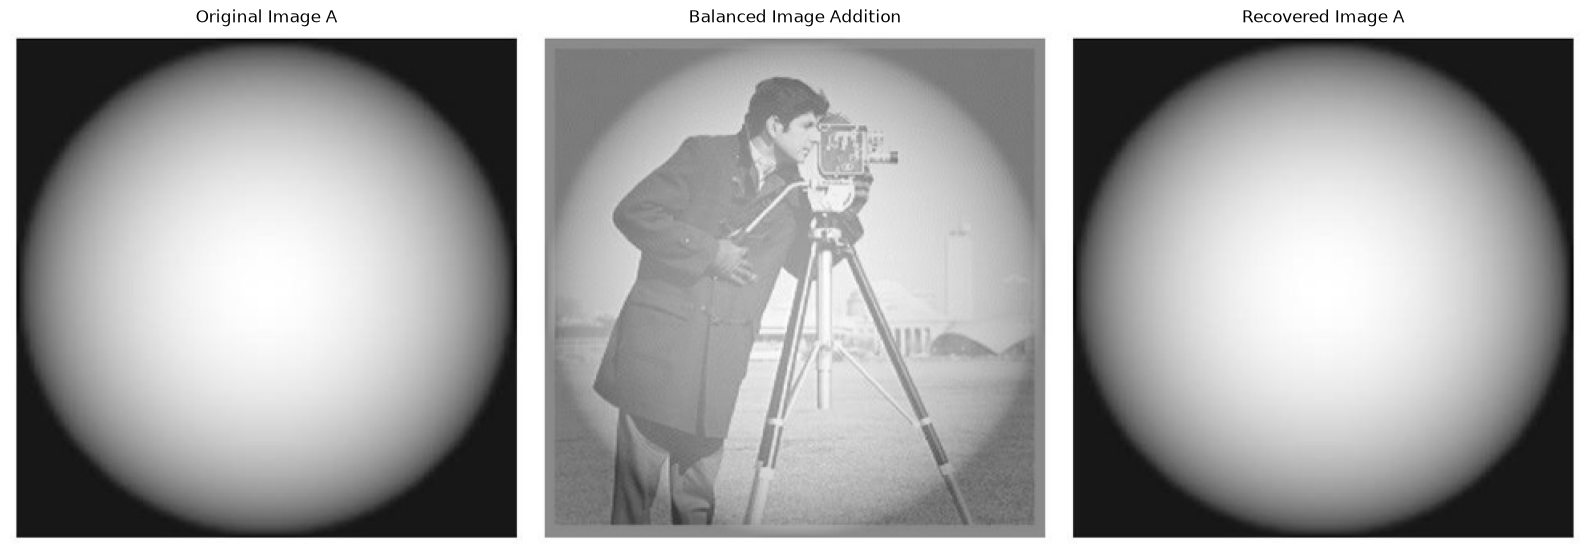

In [34]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 3, 1)
plt.imshow(A.astype(np.uint8))
plt.title("Original Image A")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(added)
plt.title("Balanced Image Addition")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(recovered)
plt.title("Recovered Image A")
plt.axis("off")

plt.tight_layout()
plt.show()

In [35]:
image_report = pd.DataFrame({
    "Metric": [
        "Image Width",
        "Image Height",
        "Colour Channels",
        "Maximum Pixel Difference",
        "Mean Pixel Difference",
        "MSE",
        "PSNR",
        "SSIM",
        "Exact Recovery"
    ],

    "Value": [
        image_A.width,
        image_A.height,
        "RGB",
        max_difference,
        mean_difference,
        mse,
        psnr,
        ssim_value,
        exact_recovery
    ]
})

image_report.to_csv(
    "../results/tables/rgb_image_quality_report.csv",
    index=False
)

image_report

,Metric,Value
0,Image Width,320
1,Image Height,320
2,Colour Channels,RGB
3,Maximum Pixel Difference,0
4,Mean Pixel Difference,0.0
5,MSE,0.0
6,PSNR,inf
7,SSIM,1.0
8,Exact Recovery,True


In [36]:
# Recover Image B by subtracting Image A from the original sum
recovered_B = (
    sum_full - A_float
).clip(0, 255).astype(np.uint8)

# Convert recovered array into an RGB image
recovered_B_image = Image.fromarray(
    recovered_B,
    mode="RGB"
)

# Save recovered Image B
recovered_B_image.save(
    "../results/images/recovered_B.png"
)

print("Image B recovery completed!")
print("Saved: ../results/images/recovered_B.png")

# Verify exact recovery
difference_B = np.abs(
    B.astype(np.int16) - recovered_B.astype(np.int16)
)

print("\nIMAGE B RECOVERY VERIFICATION")
print("--------------------------------")
print("Maximum pixel difference:", difference_B.max())
print("Mean pixel difference:", difference_B.mean())
print("Exact recovery:", np.array_equal(B, recovered_B))

Image B recovery completed!
Saved: ../results/images/recovered_B.png

IMAGE B RECOVERY VERIFICATION
--------------------------------
Maximum pixel difference: 0
Mean pixel difference: 0.0
Exact recovery: True


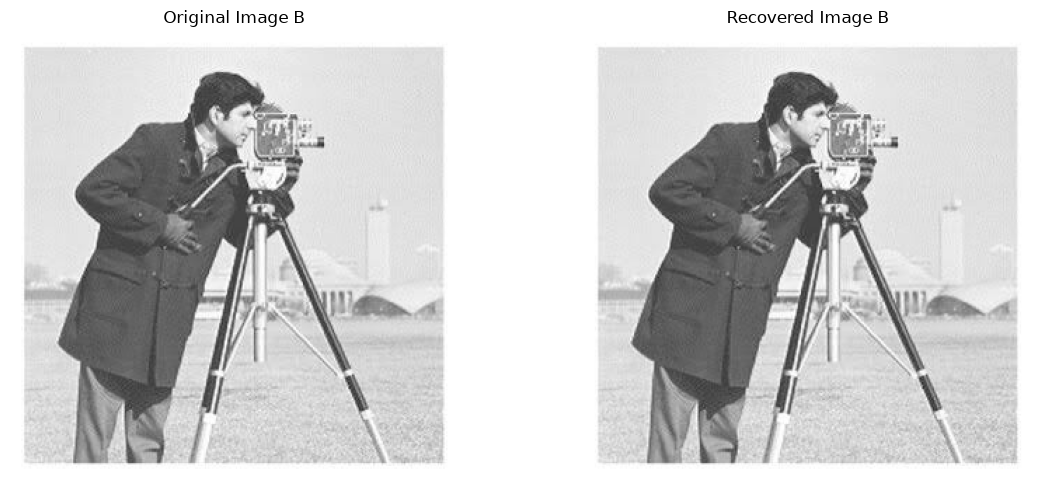

In [37]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(B.astype(np.uint8))
plt.title("Original Image B")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(recovered_B)
plt.title("Recovered Image B")
plt.axis("off")

plt.tight_layout()
plt.show()